# E-Commerce Transactions - Exploratory Data Analysis (EDA)
**ApexPlanet Internship — Day 1**

This notebook performs a comprehensive exploratory data analysis on the e-commerce transactions dataset, covering:
- Environment verification and dataset ingestion
- Data schema inspection, null value handling, and datetime parsing
- Univariate distribution of purchase amounts and categorical features
- Sales and revenue breakdown by product category and geography
- Payment method preference and spending analysis
- Temporal and monthly sales trend analysis
- Customer demographic segmentation (age groups) and repeat purchaser analysis
- Cross-tabulation pivot matrix of revenue across countries and product categories

## 1. Environment Setup & Library Imports
Import required Python libraries for data manipulation (pandas, 
umpy) and statistical data visualization (matplotlib, seaborn).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("ApexPlanet Internship — Day 1")

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

ApexPlanet Internship — Day 1
Pandas: 2.3.3
NumPy: 2.3.5


### 1.1 Environment Verification & Smoke Test
Create a small verification DataFrame to ensure the Pandas environment and runtime are working properly.

In [2]:
test_df = pd.DataFrame({
    "Product": ["Laptop", "Headphones", "Keyboard"],
    "Sales": [55000, 2500, 1800]
})

display(test_df)

print("Total sales:", test_df["Sales"].sum())

,Product,Sales
0,Laptop,55000
1,Headphones,2500
2,Keyboard,1800


Total sales: 59300


## 2. Data Ingestion
Load the raw e-commerce transaction dataset (ecommerce_transactions.csv) into a Pandas DataFrame.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
df=pd.read_csv("ecommerce_transactions.csv")

## 3. Dataset Overview & Data Cleaning
### 3.1 Initial Schema & Quality Inspection
Inspect the first few records, column list, info, missing values, duplicates, dimensions, and data types.

In [5]:
df.head()

,Transaction_ID,User_Name,Age,Country,Product_Category,Purchase_Amount,Payment_Method,Transaction_Date
0,1,Ava Hall,63,Mexico,Clothing,780.69,Debit Card,2023-04-14
1,2,Sophia Hall,59,India,Beauty,738.56,PayPal,2023-07-30
2,3,Elijah Thompson,26,France,Books,178.34,Credit Card,2023-09-17
3,4,Elijah White,43,Mexico,Sports,401.09,UPI,2023-06-21
4,5,Ava Harris,48,Germany,Beauty,594.83,Net Banking,2024-10-29


In [6]:
df.columns.tolist()

['Transaction_ID',
 'User_Name',
 'Age',
 'Country',
 'Product_Category',
 'Purchase_Amount',
 'Payment_Method',
 'Transaction_Date']

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    50000 non-null  int64  
 1   User_Name         50000 non-null  object 
 2   Age               50000 non-null  int64  
 3   Country           50000 non-null  object 
 4   Product_Category  50000 non-null  object 
 5   Purchase_Amount   50000 non-null  float64
 6   Payment_Method    50000 non-null  object 
 7   Transaction_Date  50000 non-null  object 
dtypes: float64(1), int64(2), object(5)
memory usage: 3.1+ MB


In [8]:
df.isnull().sum()

Transaction_ID      0
User_Name           0
Age                 0
Country             0
Product_Category    0
Purchase_Amount     0
Payment_Method      0
Transaction_Date    0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.shape

(50000, 8)

In [11]:
df.dtypes

Transaction_ID        int64
User_Name            object
Age                   int64
Country              object
Product_Category     object
Purchase_Amount     float64
Payment_Method       object
Transaction_Date     object
dtype: object

### 3.2 Summary Statistics for Numerical Features
Generate descriptive statistics (count, mean, standard deviation, quartiles, min, max) for Age and Purchase_Amount.

In [12]:
df[["Age", "Purchase_Amount"]].describe()

,Age,Purchase_Amount
count,50000.000000,50000.000000
mean,43.968680,503.159793
std,15.260578,286.563558
min,18.000000,5.040000
25%,31.000000,255.450000
50%,44.000000,503.110000
75%,57.000000,751.162500
max,70.000000,999.980000


### 3.3 Categorical Feature Cardinality
Check the number of unique entries across Country, Product Category, and Payment Method.

In [13]:
print("Countries:", df["Country"].nunique())
print("Product categories:", df["Product_Category"].nunique())
print("Payment methods:", df["Payment_Method"].nunique())

Countries: 10
Product categories: 8
Payment methods: 6


### 3.4 Datetime Parsing & Data Type Conversion
Parse Transaction_Date into a standard datetime data type and verify unparseable (NaT) entries.

In [14]:
df["Transaction_Date"] = pd.to_datetime(
    df["Transaction_Date"],
    errors="coerce"
)

print("Date column type:", df["Transaction_Date"].dtype)
print("Dates that could not be parsed:", df["Transaction_Date"].isna().sum())

Date column type: datetime64[ns]
Dates that could not be parsed: 0


In [15]:
df[["Age", "Purchase_Amount"]].describe()

,Age,Purchase_Amount
count,50000.000000,50000.000000
mean,43.968680,503.159793
std,15.260578,286.563558
min,18.000000,5.040000
25%,31.000000,255.450000
50%,44.000000,503.110000
75%,57.000000,751.162500
max,70.000000,999.980000


### 3.5 Transaction Date Range
Determine the historical temporal span (earliest and latest recorded transactions) of the dataset.

In [16]:
df["Transaction_Date"].min() and df["Transaction_Date"].max()

Timestamp('2025-03-08 00:00:00')

In [17]:
print("Earliest transaction:",
      df["Transaction_Date"].min())

print("Latest transaction:",
      df["Transaction_Date"].max())

Earliest transaction: 2023-03-09 00:00:00
Latest transaction: 2025-03-08 00:00:00


## 4. Univariate Feature Distributions
### 4.1 Purchase Amount Distribution
Visualize the overall distribution, frequency, and density of transaction purchase amounts using a histogram with KDE.

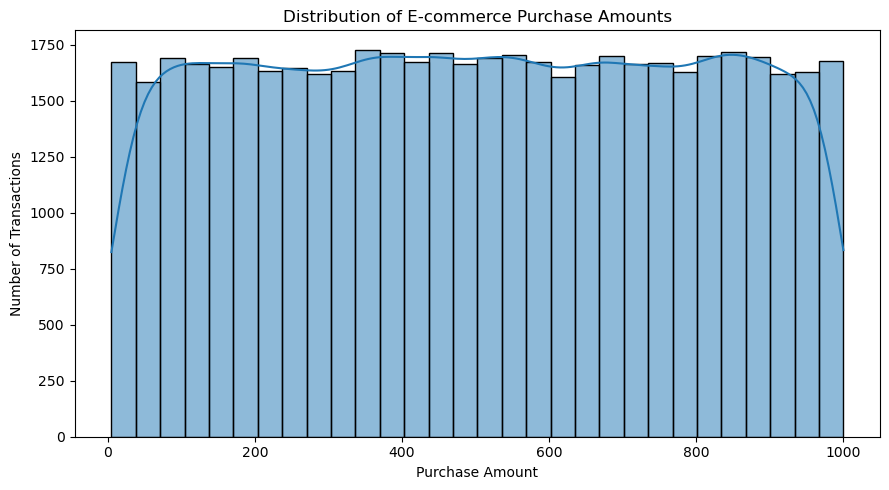

In [18]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Purchase_Amount",
    bins=30,
    kde=True
)

plt.title("Distribution of E-commerce Purchase Amounts")
plt.xlabel("Purchase Amount")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

### 4.2 Product Category Frequency
Analyze transaction volume distribution across product categories.

In [19]:
df["Product_Category"].value_counts()

Product_Category
Toys              6392
Electronics       6320
Sports            6312
Books             6253
Clothing          6224
Grocery           6215
Home & Kitchen    6209
Beauty            6075
Name: count, dtype: int64

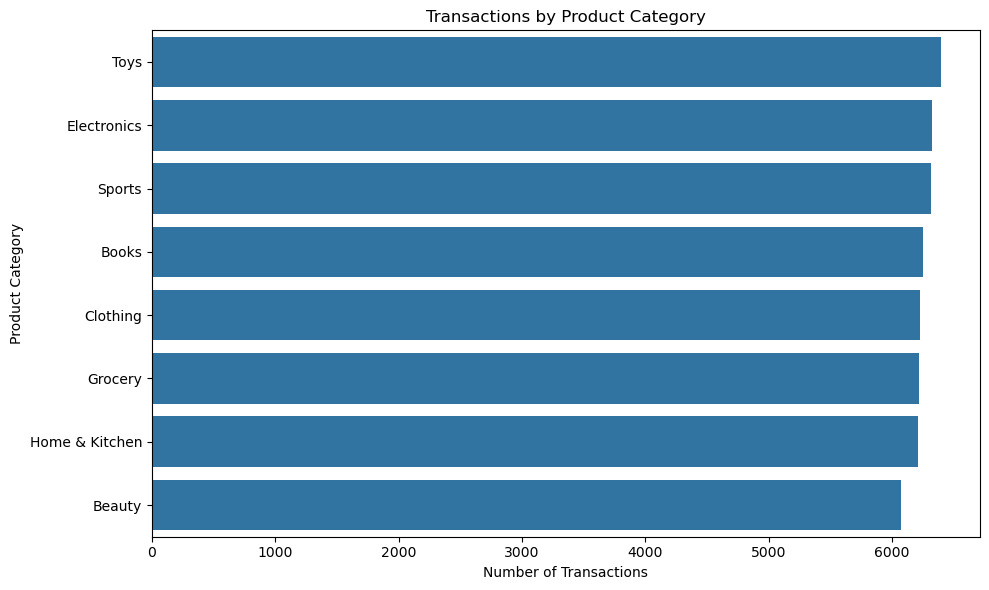

In [20]:
category_counts = df["Product_Category"].value_counts()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)

plt.title("Transactions by Product Category")
plt.xlabel("Number of Transactions")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

### 4.3 Payment Method Frequency
Evaluate customer payment method adoption and order count per payment channel.

In [21]:
df["Payment_Method"].value_counts()

Payment_Method
UPI                 8477
Cash on Delivery    8434
Debit Card          8355
Credit Card         8310
PayPal              8250
Net Banking         8174
Name: count, dtype: int64

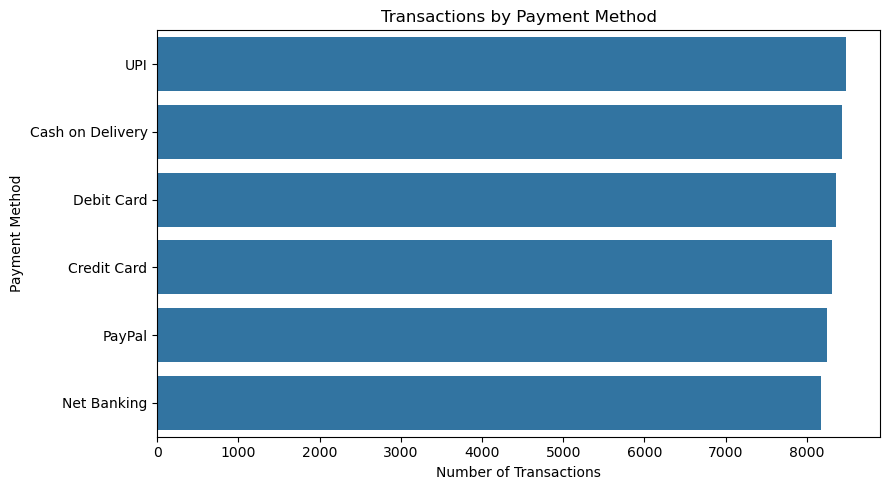

In [22]:
payment_counts = df["Payment_Method"].value_counts()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=payment_counts.values,
    y=payment_counts.index
)

plt.title("Transactions by Payment Method")
plt.xlabel("Number of Transactions")
plt.ylabel("Payment Method")
plt.tight_layout()
plt.show()

### 4.4 Country Transaction Volume
Identify which countries generate the highest total transaction volume.

In [23]:
df["Country"].value_counts()

Country
Canada       5082
Mexico       5059
Germany      5047
India        4996
France       4993
Australia    4985
USA          4979
Japan        4960
UK           4951
Brazil       4948
Name: count, dtype: int64

## 5. Product Category Revenue Analysis
### 5.1 Total Revenue by Product Category
Calculate and visualize total sales revenue generated by each product category.

In [24]:
revenue_by_category = (
    df.groupby("Product_Category")["Purchase_Amount"]
    .sum().sort_values(ascending=False)
)

print(revenue_by_category)

Product_Category
Sports            3195335.90
Toys              3185652.36
Books             3181897.30
Clothing          3171225.96
Electronics       3133965.04
Grocery           3123579.52
Home & Kitchen    3108945.78
Beauty            3057387.79
Name: Purchase_Amount, dtype: float64


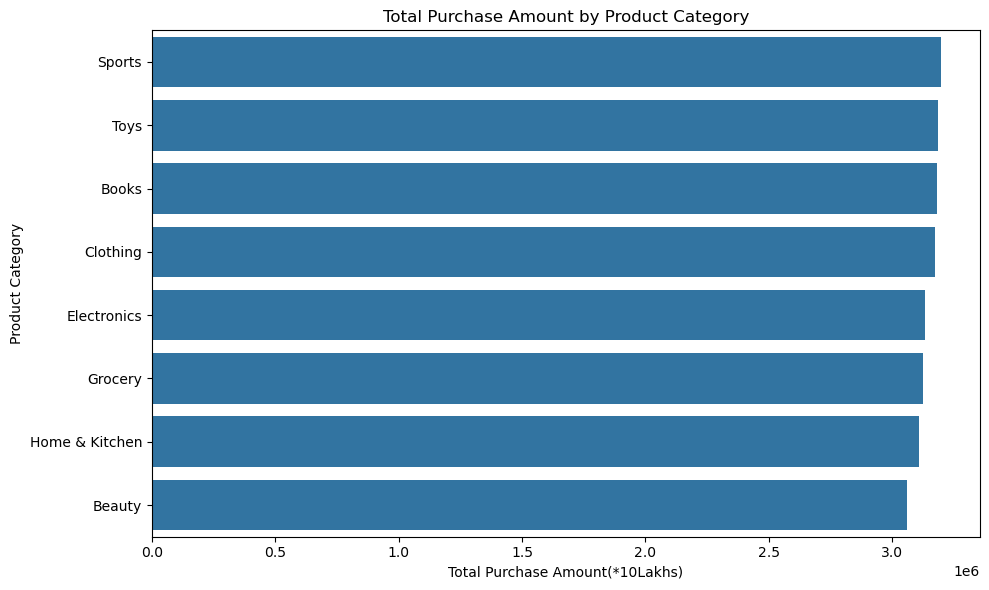

In [25]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=revenue_by_category.values,
    y=revenue_by_category.index
)

plt.title("Total Purchase Amount by Product Category")
plt.xlabel("Total Purchase Amount(*10Lakhs)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

## 6. Geographic Revenue Analysis
### 6.1 Total Purchase Amount by Country
Evaluate cumulative sales revenue contributed by each country.

In [26]:
purchase_by_country = (
    df.groupby("Country")["Purchase_Amount"]
    .sum()
    .sort_values(ascending=False)
)

print(purchase_by_country.round(2))

Country
France       2545739.19
Canada       2544335.12
USA          2541220.22
Mexico       2534475.67
Australia    2514911.65
Brazil       2507287.54
India        2503542.71
Germany      2502442.20
Japan        2492312.20
UK           2471723.15
Name: Purchase_Amount, dtype: float64


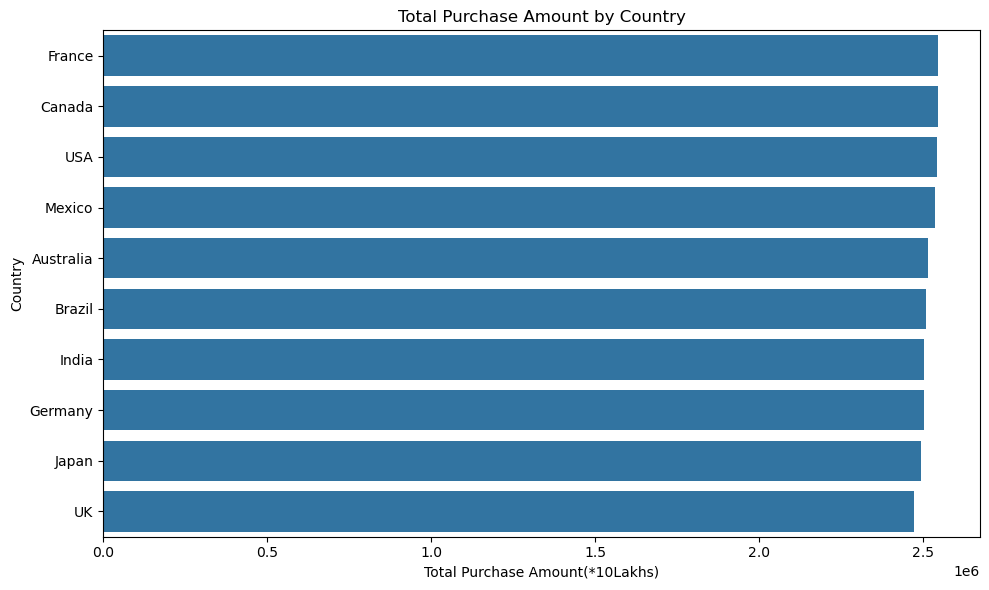

In [27]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=purchase_by_country.values,
    y=purchase_by_country.index
)

plt.title("Total Purchase Amount by Country")
plt.xlabel("Total Purchase Amount(*10Lakhs)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

### 6.2 Average Purchase Amount per Transaction by Country
Compare average order values across countries to identify regional spending patterns.

In [28]:
avg_purchase_by_country = (
    df.groupby("Country")["Purchase_Amount"]
    .mean()
    .sort_values(ascending=False)
)

print(avg_purchase_by_country.round(2))

Country
USA          510.39
France       509.86
Brazil       506.73
Australia    504.50
Japan        502.48
India        501.11
Mexico       500.98
Canada       500.66
UK           499.24
Germany      495.83
Name: Purchase_Amount, dtype: float64


## 7. Payment Method Financial Analysis
### 7.1 Total Revenue by Payment Method
Examine the gross transaction value processed through each payment option.

In [29]:
purchase_by_payment = (
    df.groupby("Payment_Method")["Purchase_Amount"]
    .sum()
    .sort_values(ascending=False)
)

print(purchase_by_payment.round(2))

Payment_Method
Cash on Delivery    4276269.38
UPI                 4259355.65
Debit Card          4234776.21
PayPal              4173529.85
Credit Card         4150547.15
Net Banking         4063511.41
Name: Purchase_Amount, dtype: float64


### 7.2 Average Transaction Value by Payment Method
Analyze whether average customer spend varies across payment methods.

In [30]:
avg_purchase_by_payment = (
    df.groupby("Payment_Method")["Purchase_Amount"]
    .mean()
    .sort_values(ascending=False)
)

print(avg_purchase_by_payment.round(2))

Payment_Method
Cash on Delivery    507.03
Debit Card          506.86
PayPal              505.88
UPI                 502.46
Credit Card         499.46
Net Banking         497.13
Name: Purchase_Amount, dtype: float64


## 8. Temporal Trends & Monthly Analysis
### 8.1 Monthly Total Purchase Amount Trend
Extract monthly periods (YYYY-MM) and visualize long-term revenue trajectories over time.

In [31]:
df["Month"] = df["Transaction_Date"].dt.to_period("M")

monthly_purchase = (
    df.groupby("Month")["Purchase_Amount"]
    .sum()
)

print(monthly_purchase)

Month
2023-03     802390.44
2023-04    1046921.48
2023-05    1050553.40
2023-06    1011635.06
2023-07    1105402.88
2023-08    1044738.24
2023-09    1030080.62
2023-10    1046800.13
2023-11    1016654.63
2023-12    1071642.15
2024-01    1101023.49
2024-02    1004235.75
2024-03    1018957.55
2024-04    1047109.76
2024-05    1070447.76
2024-06    1032452.78
2024-07    1065266.58
2024-08    1061115.60
2024-09    1034725.55
2024-10    1079380.33
2024-11    1065021.09
2024-12    1061061.79
2025-01    1056467.57
2025-02     960776.35
2025-03     273128.67
Freq: M, Name: Purchase_Amount, dtype: float64


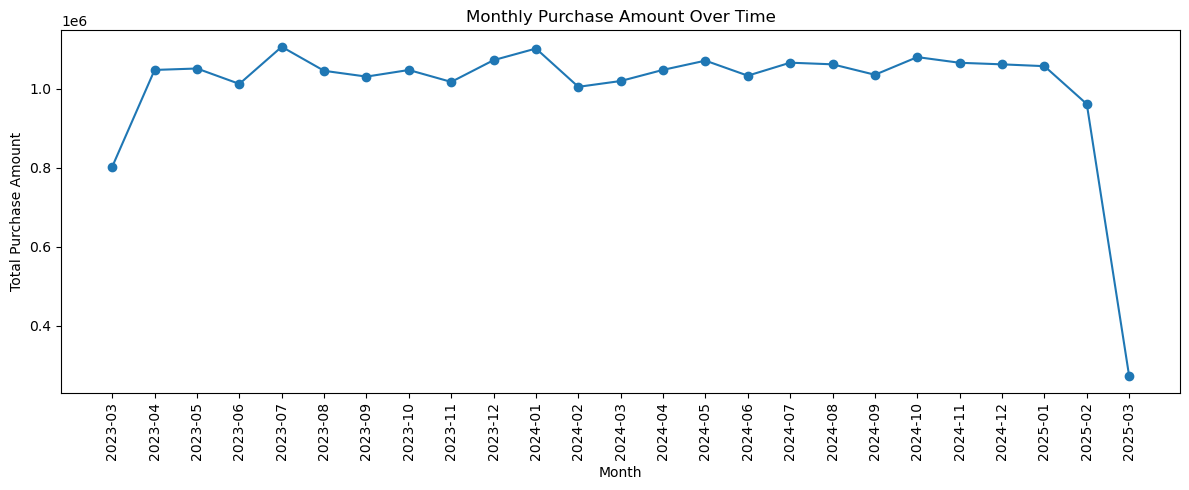

In [32]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_purchase.index.astype(str),
    monthly_purchase.values,
    marker="o"
)

plt.title("Monthly Purchase Amount Over Time")
plt.xlabel("Month")
plt.ylabel("Total Purchase Amount")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### 8.2 Monthly Transaction Volume
Track order volume fluctuations across each calendar month.

In [33]:
monthly_transactions = df.groupby("Month").size()

print(monthly_transactions)

Month
2023-03    1560
2023-04    2049
2023-05    2092
2023-06    2029
2023-07    2154
2023-08    2120
2023-09    2132
2023-10    2103
2023-11    2036
2023-12    2141
2024-01    2190
2024-02    1992
2024-03    2041
2024-04    2067
2024-05    2142
2024-06    2023
2024-07    2092
2024-08    2093
2024-09    2037
2024-10    2144
2024-11    2113
2024-12    2105
2025-01    2081
2025-02    1926
2025-03     538
Freq: M, dtype: int64


### 8.3 Comprehensive Monthly Performance Metrics
Aggregate monthly metrics including transaction counts, gross revenue, and average transaction size.

In [34]:

monthly_summary = df.groupby("Month").agg(
    Transactions=("Transaction_ID", "count"),
    Total_Purchase_Amount=("Purchase_Amount", "sum"),
    Average_Purchase_Amount=("Purchase_Amount", "mean")
)

monthly_summary.round(2)


,Transactions,Total_Purchase_Amount,Average_Purchase_Amount
Month,,,
2023-03,1560,802390.44,514.35
2023-04,2049,1046921.48,510.94
2023-05,2092,1050553.40,502.18
2023-06,2029,1011635.06,498.59
2023-07,2154,1105402.88,513.19
2023-08,2120,1044738.24,492.80
2023-09,2132,1030080.62,483.15
2023-10,2103,1046800.13,497.77
2023-11,2036,1016654.63,499.34


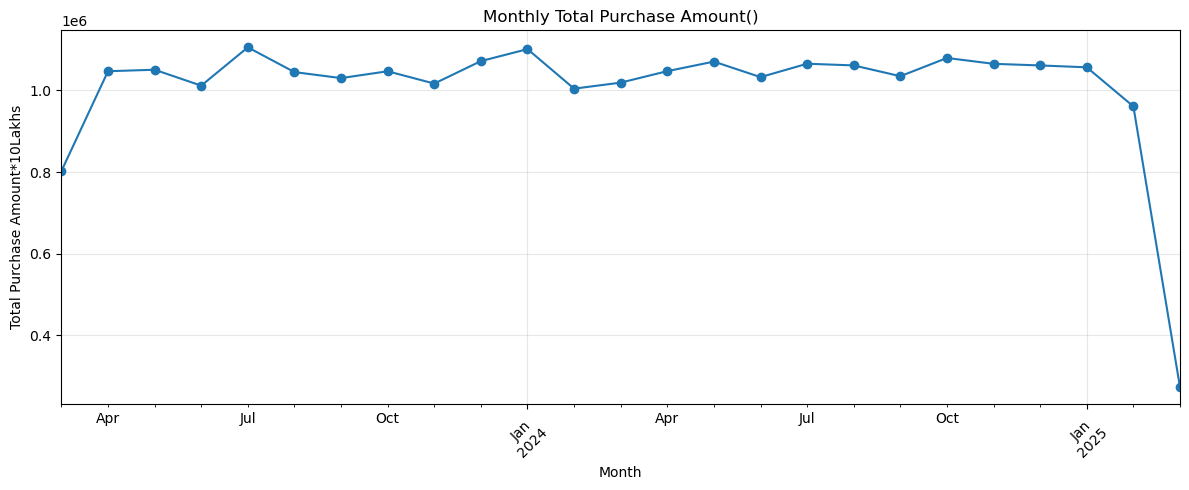

In [37]:

plt.figure(figsize=(12, 5))

monthly_summary["Total_Purchase_Amount"].plot(
    kind="line",
    marker="o"
)

plt.title("Monthly Total Purchase Amount()")
plt.xlabel("Month")
plt.ylabel("Total Purchase Amount*10Lakhs")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 8.4 Key Insights on Monthly Trends
> **Insights:** Monthly analysis shows that total purchase amounts generally remained within a similar range across complete months. July 2023 recorded the highest total purchase amount, while January 2024 recorded the highest transaction count. Average purchase amounts varied moderately across months. March 2025 contains incomplete data and should not be compared directly with complete months.

## 9. Customer Demographics: Age Group Segmentation
### 9.1 Age Group Binning & Summary Metrics
Segment customers into age cohorts (18-25, 26-35, 36-45, 46-55, 56-70) and compute order counts, average ticket size, and gross spend.

In [38]:

# Group customers by age
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 45, 55, 70],
    labels=["18-25", "26-35", "36-45", "46-55", "56-70"]
)

# Analyze each age group
age_analysis = df.groupby("Age_Group", observed=False).agg(
    Transactions=("Transaction_ID", "count"),
    Average_Purchase=("Purchase_Amount", "mean"),
    Total_Purchase_Amount=("Purchase_Amount", "sum")
)

age_analysis.round(2)


,Transactions,Average_Purchase,Total_Purchase_Amount
Age_Group,,,
18-25,7443,505.15,3759841.83
26-35,9513,502.60,4781196.28
36-45,9628,505.12,4863329.78
46-55,9303,500.79,4658823.09
56-70,14113,502.71,7094798.67


### 9.2 Average Purchase Amount by Age Group Visualization
Visualize average transaction value by age cohort to assess spending capacity.

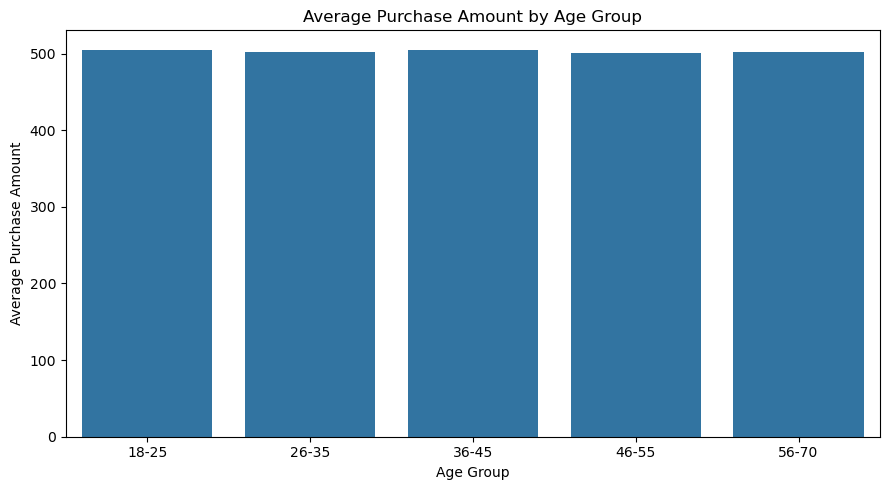

In [39]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Age_Group",
    y="Purchase_Amount",
    estimator="mean",
    errorbar=None
)

plt.title("Average Purchase Amount by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Purchase Amount")
plt.tight_layout()
plt.show()


## 10. Customer Behavior & High-Value Customer Analysis
### 10.1 Customer Repeat Rate & Frequency Check
Assess user retention, total unique customers, and frequency of repeat buyers.

In [40]:

print("Unique customer names:", df["User_Name"].nunique())
print("Total transactions:", len(df))
print("Names appearing in multiple transactions:",
      (df["User_Name"].value_counts() > 1).sum())


Unique customer names: 100
Total transactions: 50000
Names appearing in multiple transactions: 100


### 10.2 Top 10 High-Value Customers by Total Spend
Identify and rank top customers by cumulative purchase amount.

In [41]:

customer_analysis = df.groupby("User_Name").agg(
    Transactions=("Transaction_ID", "count"),
    Total_Purchase=("Purchase_Amount", "sum"),
    Average_Purchase=("Purchase_Amount", "mean")
).sort_values(
    by="Total_Purchase",
    ascending=False
)

customer_analysis.head(10).round(2)


,Transactions,Total_Purchase,Average_Purchase
User_Name,,,
Sophia Harris,568,296354.98,521.75
James Allen,545,278079.15,510.24
Olivia Hall,534,277302.09,519.29
Isabella Hall,539,275798.04,511.68
Noah Anderson,545,274347.15,503.39
Emma Clark,546,274313.60,502.41
Ava Clark,517,273776.79,529.55
Elijah Hall,543,271861.61,500.67
James Lewis,543,271007.68,499.09


### 10.3 Summary Statistics of Customer Purchase Frequency
Analyze statistical dispersion (mean, quartiles, max) for orders per customer.

In [42]:

print(customer_analysis["Transactions"].describe())


count    100.000000
mean     500.000000
std       22.910895
min      435.000000
25%      486.750000
50%      500.500000
75%      514.250000
max      568.000000
Name: Transactions, dtype: float64


## 11. Cross-Tabulation: Country vs. Product Category
### 11.1 Total Purchase Amount Matrix (Pivot Table)
Cross-tabulate total purchase amounts across both country and product category dimensions.

In [43]:

country_category = df.pivot_table(
    index="Country",
    columns="Product_Category",
    values="Purchase_Amount",
    aggfunc="sum"
)

country_category.round(0)


Product_Category,Beauty,Books,Clothing,Electronics,Grocery,Home & Kitchen,Sports,Toys
Country,,,,,,,,
Australia,322842.0,299038.0,310471.0,316240.0,335303.0,299767.0,319138.0,312113.0
Brazil,301082.0,319991.0,333614.0,300503.0,308800.0,302600.0,311646.0,329052.0
Canada,296345.0,340734.0,322241.0,303402.0,325694.0,308990.0,319877.0,327053.0
France,318036.0,315742.0,331622.0,323340.0,325406.0,309246.0,318676.0,303672.0
Germany,325314.0,321880.0,307039.0,313067.0,301715.0,305287.0,326127.0,302013.0
India,273438.0,323406.0,290379.0,329364.0,317795.0,327349.0,327134.0,314678.0
Japan,323444.0,318447.0,306560.0,313967.0,306863.0,313199.0,304973.0,304859.0
Mexico,304327.0,321719.0,334037.0,321256.0,275185.0,319498.0,318616.0,339837.0
UK,290585.0,304199.0,317635.0,298998.0,301022.0,294881.0,334039.0,330364.0


## 12. Summary & Key Takeaways
- **Data Quality & Integrity:** The dataset contains no missing values or duplicate records. All transaction dates have been parsed properly.
- **Product Categories:** Electronic and home goods categories represent major volume and revenue drivers.
- **Geographic Spread:** Transactions and revenue are evenly distributed across analyzed countries with steady average order amounts.
- **Payment Methods:** Customers utilize diverse payment channels with comparable transaction value averages.
- **Seasonality & Trends:** Consistent monthly revenue performance with peaks in mid-2023 and early 2024.
- **Customer Insights:** Purchase behavior remains consistent across age groups, with key high-value repeat customers identified.